In [ ]:
!pip install -q condacolab
import condacolab
condacolab.install()


📢 Announcement 📢
condacolab==0.2 will be released soon! Try it with:

    !pip install -q https://github.com/conda-incubator/condacolab/archive/main.zip
    import condacolab
    condacolab.install()

0.2.x introduces a new installation method based on Pixi, with customizable Python versions.
This may be breaking for your workflow. If that's the case, please report it at
https://github.com/conda-incubator/condacolab and pin your `pip install` command to
condacolab==0.1 as a workaround.

✨🍰✨ Everything looks OK!


In [ ]:
!mamba install -y -q -c conda-forge pymeep matplotlib

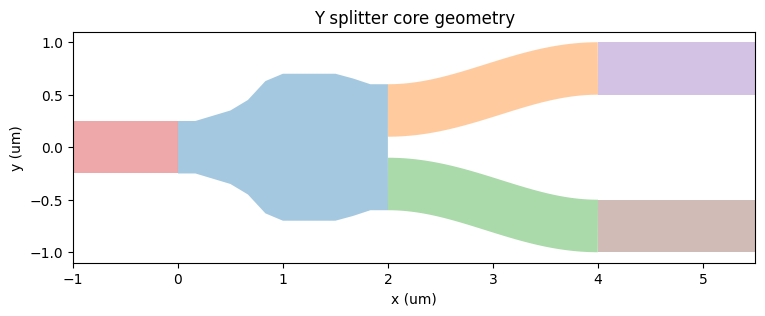

Running P0 reference ...


FloatProgress(value=0.0, description='0% done ', max=183.33333587646484)

Running P0 device ...


FloatProgress(value=0.0, description='0% done ', max=183.33333587646484)

Running P1 reference ...


FloatProgress(value=0.0, description='0% done ', max=183.33333587646484)

Running P1 device ...


FloatProgress(value=0.0, description='0% done ', max=183.33333587646484)

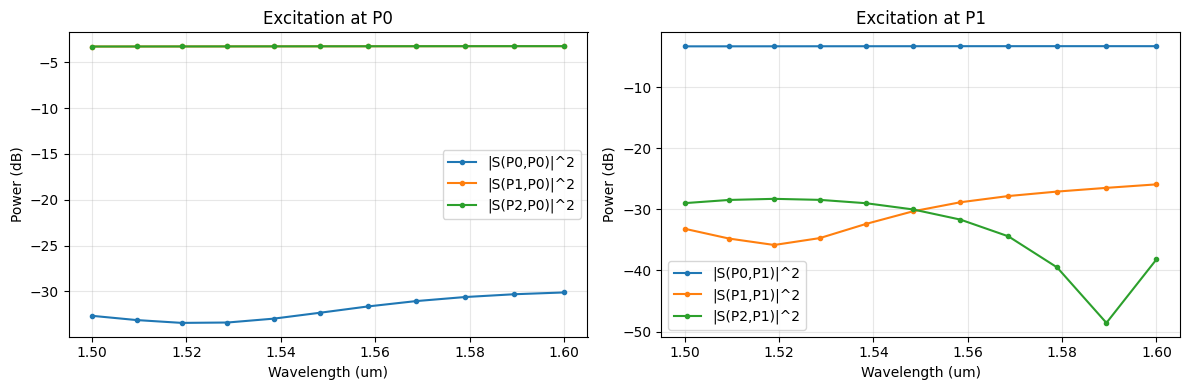

Mean insertion loss (1.5-1.6 um): 0.244 dB
Mean split imbalance P1 vs P2   : 0.000 dB
Mean return loss at P0          : 32.0 dB


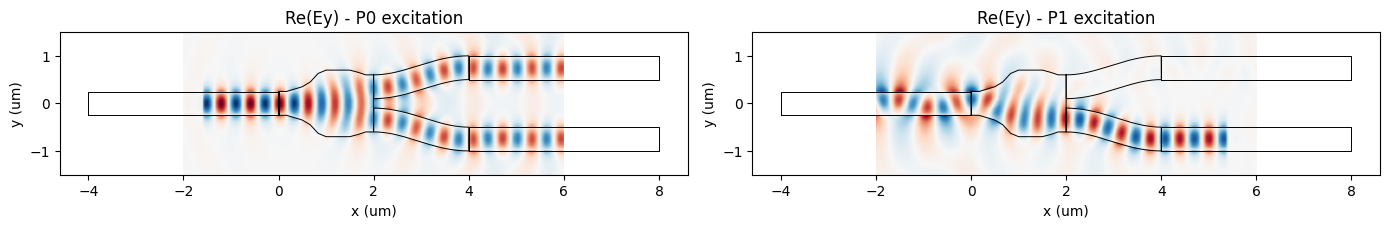

Saved Y_Splitter_meep_results.npz
GDS written; cells: ['Y_SPLITTER'] | polygons: 5


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import meep as mp

try:
    mp.verbosity(0)
except Exception:
    pass

# =====================================================================
# 0. Switches
# =====================================================================
THREE_D = False            # False: fast 2D effective-index model; True: full 3D (slow!)
RES = 24 if THREE_D else 40  # pixels per micron

# =====================================================================
# 1. "Technology": materials (Meep units: 1 length unit = 1 um, c = 1)
# =====================================================================
n_clad = 1.444             # SiO2
n_si = 3.476               # Si at 1.55 um
n_eff_slab = 2.85          # effective index of a 220 nm Si slab (TE) for the 2D model
h_si = 0.22                # Si thickness (um)

n_core = n_si if THREE_D else n_eff_slab
Si = mp.Medium(index=n_core)
SiO2 = mp.Medium(index=n_clad)
PARITY = mp.EVEN_Z         # TE-like modes (in-plane E field), band 1 = fundamental

# =====================================================================
# 2. Geometry (values from the optimized Y splitter)
# =====================================================================
w = np.array((0.5, 0.5, 0.6, 0.7, 0.9, 1.26, 1.4, 1.4, 1.4, 1.4, 1.31, 1.2, 1.2))
length = 2.0
y_out = 0.35

core_width = 0.5
clad_width = 2.5
clad_margin = (clad_width - core_width) / 2
s_offset = clad_width / 2 - clad_margin / 2 - y_out   # = 0.4
s_length = 5 * s_offset                               # = 2.0
y_port = y_out + s_offset                             # = 0.75
x_end = length + s_length                             # = 4.0


def main_polygon():
    xs = np.linspace(0, length, len(w))
    lower = np.column_stack((xs, -0.5 * w))
    upper = lower[::-1] * np.array([1.0, -1.0])
    return np.vstack((lower, upper))


def s_bend_polygon(y0, offset, n=120):
    """S bend (raised-cosine centerline) as a closed polygon of width core_width."""
    t = np.linspace(0, 1, n)
    xc = length + s_length * t
    yc = y0 + offset * (1 - np.cos(np.pi * t)) / 2
    dx, dy = np.gradient(xc), np.gradient(yc)
    nrm = np.hypot(dx, dy)
    nx, ny = -dy / nrm, dx / nrm
    up = np.column_stack((xc + nx * core_width / 2, yc + ny * core_width / 2))
    lo = np.column_stack((xc - nx * core_width / 2, yc - ny * core_width / 2))
    return np.vstack((up, lo[::-1]))


poly_main = main_polygon()
poly_top = s_bend_polygon(+y_out, +s_offset)   # ends at y = +0.75
poly_bot = s_bend_polygon(-y_out, -s_offset)   # ends at y = -0.75


def rect(x0, x1, yc):
    h = core_width / 2
    return np.array([[x0, yc - h], [x1, yc - h], [x1, yc + h], [x0, yc + h]])


# straight access waveguides (they run into the PML)
rect_in = rect(-4.0, 0.0, 0.0)
rect_top = rect(x_end, 8.0, +y_port)
rect_bot = rect(x_end, 8.0, -y_port)
outlines = [poly_main, poly_top, poly_bot, rect_in, rect_top, rect_bot]

# --- geometry preview (like the first plot of the original example)
fig, ax = plt.subplots(figsize=(9, 3))
for o in outlines:
    ax.fill(o[:, 0], o[:, 1], alpha=0.4)
ax.set_xlim(-1, 5.5); ax.set_aspect("equal")
ax.set_xlabel("x (um)"); ax.set_ylabel("y (um)"); ax.set_title("Y splitter core geometry")
plt.show()

# =====================================================================
# 3. Meep geometry helpers
# =====================================================================
if THREE_D:
    h_geo, z_base, blk_z = h_si, -0.5 * h_si, h_si
else:
    h_geo, z_base, blk_z = 1000.0, -500.0, mp.inf   # "infinite" in z for 2D


def prism(pts):
    return mp.Prism([mp.Vector3(float(x), float(y), z_base) for x, y in pts],
                    height=h_geo, material=Si)


def block(x0, x1, yc):
    return mp.Block(size=mp.Vector3(x1 - x0, core_width, blk_z),
                    center=mp.Vector3(0.5 * (x0 + x1), yc, 0), material=Si)


geom_device = [block(-4.0, 0.0, 0.0),
               prism(poly_main), prism(poly_top), prism(poly_bot),
               block(x_end, 8.0, +y_port), block(x_end, 8.0, -y_port)]
geom_ref_P0 = [block(-4.0, 8.0, 0.0)]          # straight guide at y = 0   (normalisation for P0)
geom_ref_P1 = [block(-4.0, 8.0, -y_port)]      # straight guide at y = -0.75 (normalisation for P1)

# =====================================================================
# 4. Simulation setup
# =====================================================================
dpml = 1.0
sx, sy, sz = 10.0, 5.0, 3.5
cell = mp.Vector3(sx, sy, sz if THREE_D else 0)
cell_center = mp.Vector3(2.0, 0, 0)            # cell spans x in [-3, 7]
mon_z = (sz - 2 * dpml) if THREE_D else 0

# wavelengths 1.5 - 1.6 um (as in the original); Meep frequency = 1 / wavelength
fmin, fmax = 1 / 1.6, 1 / 1.5
fmid, fspan, NF = 0.5 * (fmin + fmax), (fmax - fmin), 11
fcen_src, fwidth_src = 1 / 1.55, 0.12

X_SRC0, X_MON_IN = -1.6, -1.2        # input port P0: source / monitor
X_MON_OUT, X_SRC1 = 5.0, 5.4         # output ports: monitor / source (for P1 excitation)
T_AFTER = 100                        # run time after the source turns off


def eig_source(x, y, size_y, backward=False):
    kwargs = dict(eig_band=1, eig_parity=PARITY, eig_match_freq=True)
    if backward:
        kwargs["eig_kpoint"] = mp.Vector3(-1, 0, 0)
    return mp.EigenModeSource(mp.GaussianSource(fcen_src, fwidth=fwidth_src),
                              center=mp.Vector3(x, y, 0),
                              size=mp.Vector3(0, size_y, mon_z), **kwargs)


def run_sim(geometry, source, mons, want_field=False):
    """mons: dict name -> (center_xy, size_y). Returns (alpha dict, freqs, field)."""
    sim = mp.Simulation(cell_size=cell, geometry_center=cell_center,
                        boundary_layers=[mp.PML(dpml)], geometry=geometry,
                        sources=[source], default_material=SiO2, resolution=RES,
                        dimensions=3 if THREE_D else 2)
    mon_objs = {}
    for name, ((cx, cy), sy_m) in mons.items():
        mon_objs[name] = sim.add_mode_monitor(
            fmid, fspan, NF,
            mp.ModeRegion(center=mp.Vector3(cx, cy, 0), size=mp.Vector3(0, sy_m, mon_z)))
    dft = None
    if want_field:
        dft = sim.add_dft_fields([mp.Ey], fcen_src, 0, 1,
                                 where=mp.Volume(center=mp.Vector3(2.0, 0, 0),
                                                 size=mp.Vector3(sx - 2 * dpml, sy - 2 * dpml, 0)))
    sim.run(until_after_sources=T_AFTER)

    alphas, freqs = {}, None
    for name, mon in mon_objs.items():
        res = sim.get_eigenmode_coefficients(mon, [1], eig_parity=PARITY)
        alphas[name] = np.array(res.alpha[0])          # shape (NF, 2): [:,0] +x, [:,1] -x
        freqs = np.array(mp.get_flux_freqs(mon))
    fld = np.real(sim.get_dft_array(dft, mp.Ey, 0)) if want_field else None
    return alphas, freqs, fld


# =====================================================================
# 5. Excite P0 (input): reference run + device run
# =====================================================================
print("Running P0 reference ...")
ref0, freqs, _ = run_sim(geom_ref_P0, eig_source(X_SRC0, 0, 2.6),
                         {"in": ((X_MON_IN, 0), 2.6)})
a_ref0 = ref0["in"][:, 0]

print("Running P0 device ...")
mons_dev = {"in": ((X_MON_IN, 0), 2.6),
            "p1": ((X_MON_OUT, -y_port), 1.2),     # P1: lower output
            "p2": ((X_MON_OUT, +y_port), 1.2)}     # P2: upper output
dev0, _, field0 = run_sim(geom_device, eig_source(X_SRC0, 0, 2.6), mons_dev, want_field=True)

S = {}
S[("P0", "P0")] = dev0["in"][:, 1] / a_ref0
S[("P0", "P1")] = dev0["p1"][:, 0] / a_ref0     # transmission P0 -> P1
S[("P0", "P2")] = dev0["p2"][:, 0] / a_ref0     # transmission P0 -> P2

# =====================================================================
# 6. Excite P1 (lower output port, light travelling in -x)
# =====================================================================
field1 = None
try:
    print("Running P1 reference ...")
    ref1, _, _ = run_sim(geom_ref_P1, eig_source(X_SRC1, -y_port, 1.2, backward=True),
                         {"p1": ((X_MON_OUT, -y_port), 1.2)})
    inc_back, inc_fwd = ref1["p1"][:, 1], ref1["p1"][:, 0]
    if np.mean(np.abs(inc_back)) < 10 * np.mean(np.abs(inc_fwd)):
        raise RuntimeError("Source did not launch a backward (-x) mode; skipping P1 excitation.")

    print("Running P1 device ...")
    dev1, _, field1 = run_sim(geom_device, eig_source(X_SRC1, -y_port, 1.2, backward=True),
                              mons_dev, want_field=True)
    S[("P1", "P0")] = dev1["in"][:, 1] / inc_back     # P1 -> P0
    S[("P1", "P1")] = dev1["p1"][:, 0] / inc_back     # reflection at P1
    S[("P1", "P2")] = dev1["p2"][:, 0] / inc_back     # P1 -> P2 (crosstalk)
except Exception as e:
    print("P1 excitation skipped:", e)

# =====================================================================
# 7. S-parameter plots (|S|^2 in dB vs wavelength)
# =====================================================================
lam = 1.0 / freqs
order = np.argsort(lam)
lam = lam[order]


def dB(s):
    return 10 * np.log10(np.maximum(np.abs(s[order]) ** 2, 1e-12))


inputs = ["P0"] + (["P1"] if ("P1", "P0") in S else [])
fig, axes = plt.subplots(1, len(inputs), figsize=(6 * len(inputs), 4), squeeze=False)
for ax, src in zip(axes[0], inputs):
    for (i, j), s in S.items():
        if i == src:
            ax.plot(lam, dB(s), marker="o", ms=3, label=f"|S({j},{i})|^2")
    ax.set_title(f"Excitation at {src}")
    ax.set_xlabel("Wavelength (um)"); ax.set_ylabel("Power (dB)")
    ax.grid(True, alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

T_total = (np.abs(S[("P0", "P1")]) ** 2 + np.abs(S[("P0", "P2")]) ** 2)[order]
print(f"Mean insertion loss (1.5-1.6 um): {np.mean(-10*np.log10(T_total)):.3f} dB")
print(f"Mean split imbalance P1 vs P2   : "
      f"{np.mean(np.abs(dB(S[('P0','P1')]) - dB(S[('P0','P2')]))):.3f} dB")
print(f"Mean return loss at P0          : {np.mean(-dB(S[('P0','P0')])):.1f} dB")

# =====================================================================
# 8. Field plots (Ey at the center wavelength)
# =====================================================================
fields = [("P0 excitation", field0)] + ([("P1 excitation", field1)] if field1 is not None else [])
fig, axes = plt.subplots(1, len(fields), figsize=(7 * len(fields), 3.5), squeeze=False)
ext = [2.0 - (sx - 2 * dpml) / 2, 2.0 + (sx - 2 * dpml) / 2, -(sy - 2 * dpml) / 2, (sy - 2 * dpml) / 2]
for ax, (title, f) in zip(axes[0], fields):
    vmax = np.max(np.abs(f))
    ax.imshow(f.T, origin="lower", extent=ext, cmap="RdBu", vmin=-vmax, vmax=vmax, aspect="equal")
    for o in outlines:
        ax.plot(np.append(o[:, 0], o[0, 0]), np.append(o[:, 1], o[0, 1]), "k-", lw=0.7)
    ax.set_title(f"Re(Ey) - {title}"); ax.set_xlabel("x (um)"); ax.set_ylabel("y (um)")
plt.tight_layout(); plt.show()

# =====================================================================
# 9. Saving / exporting (replaces write_phf / write_gds)
# =====================================================================
np.savez("Y_Splitter_meep_results.npz", wavelength_um=lam,
         **{f"S_{i}_{j}": s[order] for (i, j), s in S.items()})
print("Saved Y_Splitter_meep_results.npz")

try:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gdstk"], check=True)
    import gdstk
    lib = gdstk.Library()
    cell_gds = lib.new_cell("Y_SPLITTER")
    for p in (poly_main, poly_top, poly_bot):
        cell_gds.add(gdstk.Polygon([tuple(v) for v in p], layer=2, datatype=0))   # WG_CORE (2,0)
    lib.write_gds("Y_Splitter.gds")
    chk = gdstk.read_gds("Y_Splitter.gds")
    print("GDS written; cells:", [c.name for c in chk.cells],
          "| polygons:", sum(len(c.polygons) for c in chk.cells))
except Exception as e:
    print("GDS export skipped:", e)

# To download from Colab:
# from google.colab import files; files.download("Y_Splitter.gds")

In [ ]:
if not THREE_D:
    try:
        f0 = 1 / 1.55
        def wg(yc):
            return mp.Block(size=mp.Vector3(mp.inf, core_width, mp.inf),
                            center=mp.Vector3(0, yc, 0), material=Si)

        def neffs(geometry, nbands):
            sim = mp.Simulation(cell_size=mp.Vector3(1, 5, 0), geometry=geometry,
                                default_material=SiO2, resolution=RES, dimensions=2)
            sim.init_sim()
            vol = mp.Volume(center=mp.Vector3(), size=mp.Vector3(0, 4, 0))
            out = []
            for b in range(1, nbands + 1):
                em = sim.get_eigenmode(freq=f0, direction=mp.X, where=vol, band_num=b,
                                       kpoint=mp.Vector3(2.4 * f0, 0, 0), parity=PARITY)
                out.append(em.k.x / f0)
            return out

        print("Isolated waveguide n_eff :", neffs([wg(0)], 1))
        print("Coupled pair n_eff (2 modes):", neffs([wg(+y_out), wg(-y_out)], 2))
    except Exception as e:
        print("Mode demo skipped:", e)

Mode demo skipped: Simulation.get_eigenmode() got an unexpected keyword argument 'freq'


In [ ]:
!pip install -q condacolab
import condacolab
condacolab.install()

✨🍰✨ Everything looks OK!


In [ ]:
!mamba install -y -q -c conda-forge pymeep matplotlib ipywidgets

In [ ]:
import meep as mp
print("Meep version:", mp.__version__)

Meep version: 1.35.0


2D effective core index (220 nm slab, TE): 2.8478


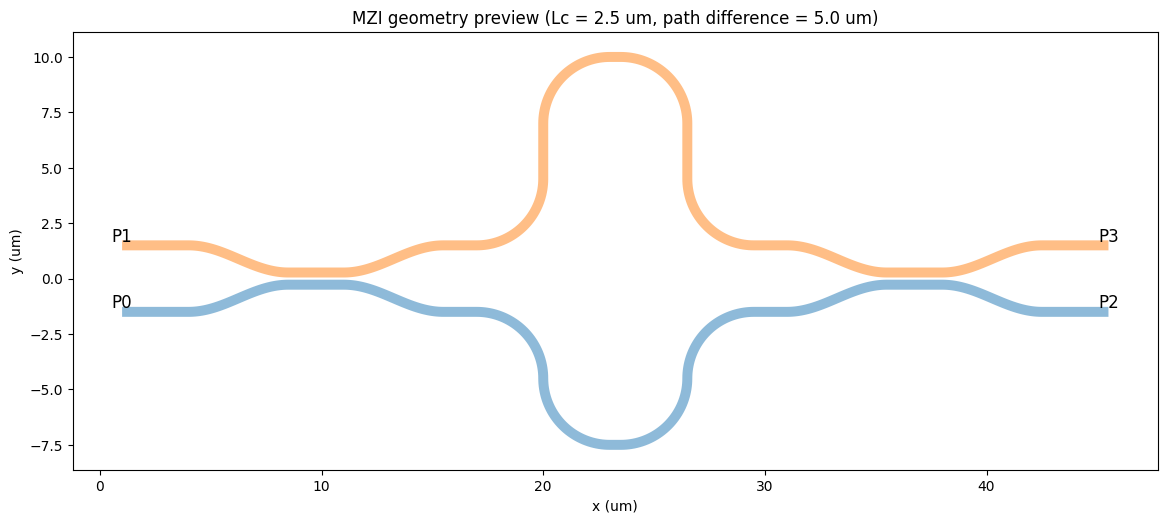

In [ ]:
import time
import numpy as np
import matplotlib.pyplot as plt
import meep as mp

try:
    mp.verbosity(0)
except Exception:
    pass

# ======================= switches =======================
QUICK_TEST = False     # True = low resolution, just to test that everything runs
CALIBRATE = True       # sweep coupler length to find the 50:50 point
LC_MANUAL = 2.5        # used if CALIBRATE = False (um)
RUN_P1 = True          # also excite the second input port
DL = 5.0               # path-length difference (um), as single_mzi(5) in the original

RES = 20 if QUICK_TEST else 32     # pixels per um
NF = 21 if QUICK_TEST else 51      # number of wavelength points
PARITY = mp.EVEN_Z                 # TE-like mode, band 1 = fundamental

# ======================= technology =======================
t_si, n_clad, n_si = 0.22, 1.444, 3.476


def slab_neff(t, n1=n_si, n2=n_clad, lam0=1.55):
    """Effective index of the TE0 mode of a symmetric slab of thickness t (um)."""
    k0 = 2 * np.pi / lam0
    a = k0 * t / 2
    V = a * np.sqrt(n1 ** 2 - n2 ** 2)
    lo, hi = 1e-9, min(V, np.pi / 2 - 1e-9)
    f = lambda u: u * np.tan(u) - np.sqrt(max(V ** 2 - u ** 2, 0.0))
    for _ in range(200):
        mid = 0.5 * (lo + hi)
        if f(mid) > 0:
            hi = mid
        else:
            lo = mid
    u = 0.5 * (lo + hi)
    return float(np.sqrt(n1 ** 2 - (u / a) ** 2))


n_core = slab_neff(t_si)
print(f"2D effective core index (220 nm slab, TE): {n_core:.4f}")
Si2D = mp.Medium(index=n_core)
SiO2 = mp.Medium(index=n_clad)

# ======================= geometry parameters (um) =======================
w = 0.45                    # strip core width
gap = 0.1                   # coupler edge-to-edge gap
g = (w + gap) / 2           # half centre-to-centre distance in the coupler
hs = 1.5                    # port half-separation (ports at y = +-hs)
D_CPL = hs - g
Ls = 4.5                    # coupler S-bend length
R_BEND = 3.0                # arm bend radius (as in the original)
Lb = 0.5                    # short straight between arm bends
Lg = 1.5                    # straight between coupler and arm
V0 = 0.0                    # vertical leg of the reference arm

# ======================= simulation constants =======================
dpml = 1.0
fmin, fmax = 1 / 1.6, 1 / 1.5
fmid, fspan = 0.5 * (fmin + fmax), fmax - fmin
fcen_src, fwidth_src = 1 / 1.55, 0.12
x_src, x_mon_in, xc0 = 1.6, 2.2, 4.0
src_size = 1.6
NG_EST = 3.3                # conservative group index, only used to choose run time


# ======================= centerline builder =======================
class CL:
    def __init__(self, x, y):
        self.x, self.y, self.th = float(x), float(y), 0.0
        self.p = [np.array([[self.x, self.y]])]

    def straight(self, L):
        if L > 1e-12:
            self.x += L * np.cos(self.th)
            self.y += L * np.sin(self.th)
            self.p.append(np.array([[self.x, self.y]]))
        return self

    def sbend(self, L, dy, n=60):
        assert abs(self.th) < 1e-9, "S-bend only valid for heading +x"
        t = np.linspace(0, 1, n + 1)[1:]
        pts = np.column_stack((self.x + L * t, self.y + dy * (1 - np.cos(np.pi * t)) / 2))
        self.p.append(pts)
        self.x += L
        self.y += dy
        return self

    def arc(self, R, ang, n=40):          # ang > 0: left turn, ang < 0: right turn
        sg = np.sign(ang)
        cx = self.x - sg * R * np.sin(self.th)
        cy = self.y + sg * R * np.cos(self.th)
        a0 = np.arctan2(self.y - cy, self.x - cx)
        a = a0 + np.linspace(0, ang, n + 1)[1:]
        pts = np.column_stack((cx + R * np.cos(a), cy + R * np.sin(a)))
        self.p.append(pts)
        self.x, self.y = float(pts[-1, 0]), float(pts[-1, 1])
        self.th += ang
        return self

    def pts(self):
        return np.vstack(self.p)


def to_polygon(c, width):
    x, y = c[:, 0], c[:, 1]
    dx, dy = np.gradient(x), np.gradient(y)
    nrm = np.hypot(dx, dy)
    nx, ny = -dy / nrm, dx / nrm
    up = np.column_stack((x + nx * width / 2, y + ny * width / 2))
    lo = np.column_stack((x - nx * width / 2, y - ny * width / 2))
    return np.vstack((up, lo[::-1]))


def prism(poly):
    return mp.Prism([mp.Vector3(float(x), float(y), -500.0) for x, y in poly],
                    height=1000.0, material=Si2D)


def mzi_dims(Lc, DLx):
    Vu = V0 + DLx / 2.0
    x1 = xc0 + 2 * Ls + Lc
    x2s = x1 + Lg + 4 * R_BEND + Lb + Lg
    x2e = x2s + 2 * Ls + Lc
    xmo = x2e + 1.2
    xmax = xmo + 0.8 + dpml
    ytop = hs + 2 * R_BEND + Vu + w / 2 + 0.8 + dpml
    ybot = -(hs + 2 * R_BEND + V0 + w / 2 + 0.8 + dpml)
    return dict(x2e=x2e, xmo=xmo, xmax=xmax, ytop=ytop, ybot=ybot)


def mzi_polys(Lc, DLx, x_start=-3.0, x_stop=None):
    d = mzi_dims(Lc, DLx)
    if x_stop is None:
        x_stop = d["xmax"] + 3.0
    polys = []
    for sign in (-1, +1):                       # -1: lower arm, +1: upper (delay) arm
        V = V0 + (DLx / 2.0 if sign > 0 else 0.0)
        c = CL(x_start, sign * hs)
        c.straight(xc0 - x_start)
        c.sbend(Ls, -sign * D_CPL).straight(Lc).sbend(Ls, sign * D_CPL)      # coupler 1
        c.straight(Lg)
        c.arc(R_BEND, sign * np.pi / 2).straight(V).arc(R_BEND, -sign * np.pi / 2)
        c.straight(Lb)
        c.arc(R_BEND, -sign * np.pi / 2).straight(V).arc(R_BEND, sign * np.pi / 2)
        c.straight(Lg)
        c.sbend(Ls, -sign * D_CPL).straight(Lc).sbend(Ls, sign * D_CPL)      # coupler 2
        assert abs(c.x - d["x2e"]) < 1e-6, (c.x, d["x2e"])
        c.straight(x_stop - c.x)
        polys.append(to_polygon(c.pts(), w))
    return polys


# ======================= geometry preview =======================
polys_prev = mzi_polys(LC_MANUAL, DL, x_start=xc0 - 3.0,
                       x_stop=mzi_dims(LC_MANUAL, DL)["x2e"] + 3.0)
fig, ax = plt.subplots(figsize=(14, 6))
for p in polys_prev:
    ax.fill(p[:, 0], p[:, 1], alpha=0.5)
x_left, x_right = xc0 - 3.0, mzi_dims(LC_MANUAL, DL)["x2e"] + 3.0
for name, (px, py) in {"P0": (x_left, -hs), "P1": (x_left, hs),
                       "P2": (x_right, -hs), "P3": (x_right, hs)}.items():
    ax.annotate(name, (px, py), fontsize=12, color="k", ha="center", va="bottom")
ax.set_aspect("equal"); ax.set_xlabel("x (um)"); ax.set_ylabel("y (um)")
ax.set_title(f"MZI geometry preview (Lc = {LC_MANUAL} um, path difference = {DL} um)")
plt.show()

Reference run ...


FloatProgress(value=0.0, description='0% done ', max=149.73333587646485)

   [reference] done in 3 s
Coupler sweep: Lc = 0.0 um


FloatProgress(value=0.0, description='0% done ', max=176.13333587646486)

   [Lc=0.0] done in 104 s
Coupler sweep: Lc = 2.0 um


FloatProgress(value=0.0, description='0% done ', max=182.73333587646485)

... (3 outputs left out)

FloatProgress(value=0.0, description='0% done ', max=195.93333587646484)

   [Lc=6.0] done in 124 s
Coupler sweep: Lc = 8.0 um


FloatProgress(value=0.0, description='0% done ', max=202.53333587646483)

   [Lc=8.0] done in 134 s


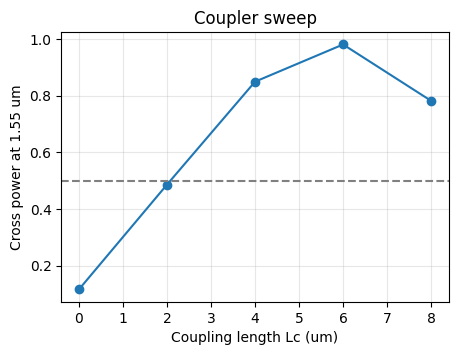

==> Using coupling length Lc = 2.077 um
Final coupler run ...


FloatProgress(value=0.0, description='0% done ', max=182.98855817553624)

   [final coupler] done in 110 s


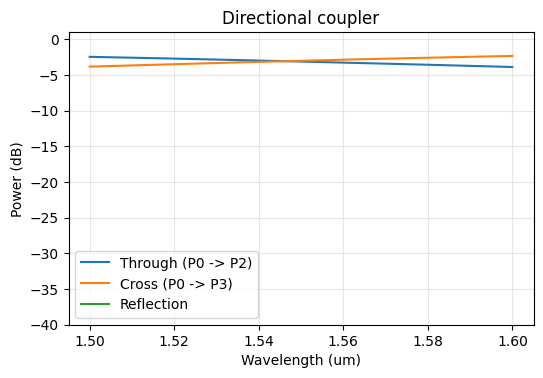

Coupler split at 1.55 um: through 0.486, cross 0.500


In [ ]:
def run_fdtd(geometry, bounds, src_y, mons, path_len, want_field=False, label=""):
    """bounds = (x0, x1, y0, y1). mons = {name: (x, y)}.
    Returns (alphas, freqs, field); alphas[name] has shape (NF, 2) = [+x, -x] amplitudes."""
    x0, x1, y0, y1 = bounds
    t0 = time.time()
    src = mp.EigenModeSource(
        mp.GaussianSource(fcen_src, fwidth=fwidth_src),
        center=mp.Vector3(x_src, src_y, 0), size=mp.Vector3(0, src_size, 0),
        eig_band=1, eig_parity=PARITY, eig_match_freq=True)
    sim = mp.Simulation(
        cell_size=mp.Vector3(x1 - x0, y1 - y0, 0),
        geometry_center=mp.Vector3(0.5 * (x0 + x1), 0.5 * (y0 + y1), 0),
        boundary_layers=[mp.PML(dpml)], geometry=geometry, sources=[src],
        default_material=SiO2, resolution=RES, dimensions=2)
    mon_objs = {}
    for name, (cx, cy) in mons.items():
        mon_objs[name] = sim.add_mode_monitor(
            fmid, fspan, NF,
            mp.ModeRegion(center=mp.Vector3(cx, cy, 0), size=mp.Vector3(0, src_size, 0)))
    dft = None
    if want_field:
        dft = sim.add_dft_fields(
            [mp.Ey], fcen_src, 0, 1,
            where=mp.Volume(center=mp.Vector3(0.5 * (x0 + x1), 0.5 * (y0 + y1), 0),
                            size=mp.Vector3(x1 - x0 - 2 * dpml, y1 - y0 - 2 * dpml, 0)))
    sim.run(until_after_sources=NG_EST * path_len + 40)
    alphas, freqs = {}, None
    for name, m in mon_objs.items():
        res = sim.get_eigenmode_coefficients(m, [1], eig_parity=PARITY)
        alphas[name] = np.array(res.alpha[0])
        freqs = np.array(mp.get_flux_freqs(m))
    fld = np.real(sim.get_dft_array(dft, mp.Ey, 0)) if want_field else None
    print(f"   [{label}] done in {time.time() - t0:.0f} s")
    return alphas, freqs, fld


# ---------- reference: straight waveguide (normalisation of the incident mode) ----------
print("Reference run ...")
c_ref = CL(-3.0, -hs).straight(14.0)
ref_out, freqs, _ = run_fdtd([prism(to_polygon(c_ref.pts(), w))], (0, 8, -4, 4), -hs,
                             {"m0": (x_mon_in, -hs)}, path_len=8, label="reference")
a_ref = ref_out["m0"][:, 0]
assert np.min(np.abs(a_ref)) > 0, "Reference amplitude is zero - source/mode problem"
lam_f = 1.0 / freqs
idx_c = int(np.argmin(np.abs(freqs - 1 / 1.55)))


# ---------- single directional coupler ----------
def coupler_run(Lc, label=""):
    x_end = xc0 + 2 * Ls + Lc
    x_mon_out = x_end + 1.2
    x_max = x_mon_out + 0.8 + dpml
    geo = []
    for sign in (-1, +1):
        c = CL(-3.0, sign * hs).straight(xc0 + 3.0)
        c.sbend(Ls, -sign * D_CPL).straight(Lc).sbend(Ls, sign * D_CPL)
        c.straight(x_max + 3.0 - c.x)
        geo.append(prism(to_polygon(c.pts(), w)))
    ycl = hs + w / 2 + 0.8 + dpml
    mons = {"m0": (x_mon_in, -hs), "m1": (x_mon_in, hs),
            "m2": (x_mon_out, -hs), "m3": (x_mon_out, hs)}
    out, _, _ = run_fdtd(geo, (0, x_max, -ycl, ycl), -hs, mons, path_len=x_max, label=label)
    return dict(R=np.abs(out["m0"][:, 1] / a_ref) ** 2,
                T=np.abs(out["m2"][:, 0] / a_ref) ** 2,     # through (P0 -> P2)
                K=np.abs(out["m3"][:, 0] / a_ref) ** 2)     # cross   (P0 -> P3)


def pick_Lc(lengths, Pc):
    if Pc[0] >= 0.5:
        print("WARNING: even Lc = 0 gives >= 50% coupling. Increase 'gap' and re-run.")
        return 0.0
    for i in range(len(Pc) - 1):
        if (Pc[i] - 0.5) * (Pc[i + 1] - 0.5) <= 0 and Pc[i] != Pc[i + 1]:
            return lengths[i] + (0.5 - Pc[i]) * (lengths[i + 1] - lengths[i]) / (Pc[i + 1] - Pc[i])
    print("WARNING: 50% never reached in the sweep; using the length of maximum coupling.")
    return lengths[int(np.argmax(Pc))]


if CALIBRATE:
    sweep = [0.0, 2.0, 4.0, 6.0, 8.0]
    Pc = []
    for L in sweep:
        print(f"Coupler sweep: Lc = {L} um")
        Pc.append(coupler_run(L, f"Lc={L}")["K"][idx_c])
    Lc_opt = float(pick_Lc(sweep, np.array(Pc)))
    plt.figure(figsize=(5, 3.5))
    plt.plot(sweep, Pc, "o-"); plt.axhline(0.5, color="gray", ls="--")
    plt.xlabel("Coupling length Lc (um)"); plt.ylabel("Cross power at 1.55 um")
    plt.title("Coupler sweep"); plt.grid(alpha=0.3); plt.show()
else:
    Lc_opt = LC_MANUAL
print(f"==> Using coupling length Lc = {Lc_opt:.3f} um")

print("Final coupler run ...")
cpl = coupler_run(Lc_opt, "final coupler")
t_c, k_c = np.sqrt(cpl["T"]), np.sqrt(cpl["K"])          # |through|, |cross| amplitudes

plt.figure(figsize=(6, 3.8))
plt.plot(lam_f, 10 * np.log10(cpl["T"]), label="Through (P0 -> P2)")
plt.plot(lam_f, 10 * np.log10(cpl["K"]), label="Cross (P0 -> P3)")
plt.plot(lam_f, 10 * np.log10(np.maximum(cpl["R"], 1e-9)), label="Reflection")
plt.xlabel("Wavelength (um)"); plt.ylabel("Power (dB)"); plt.ylim(-40, 1)
plt.grid(alpha=0.3); plt.legend(); plt.title("Directional coupler"); plt.show()
print(f"Coupler split at 1.55 um: through {cpl['T'][idx_c]:.3f}, cross {cpl['K'][idx_c]:.3f}")

MZI: exciting P0 ...


WARNING vol mismatch:, original_vol 858476, looped vol_sum 857848 


FloatProgress(value=0.0, description='0% done ', max=326.7937804746076)

   [MZI P0] done in 2822 s
MZI: exciting P1 ...
WARNING vol mismatch:, original_vol 858476, looped vol_sum 857848 


FloatProgress(value=0.0, description='0% done ', max=326.7937804746076)

   [MZI P1] done in 2813 s


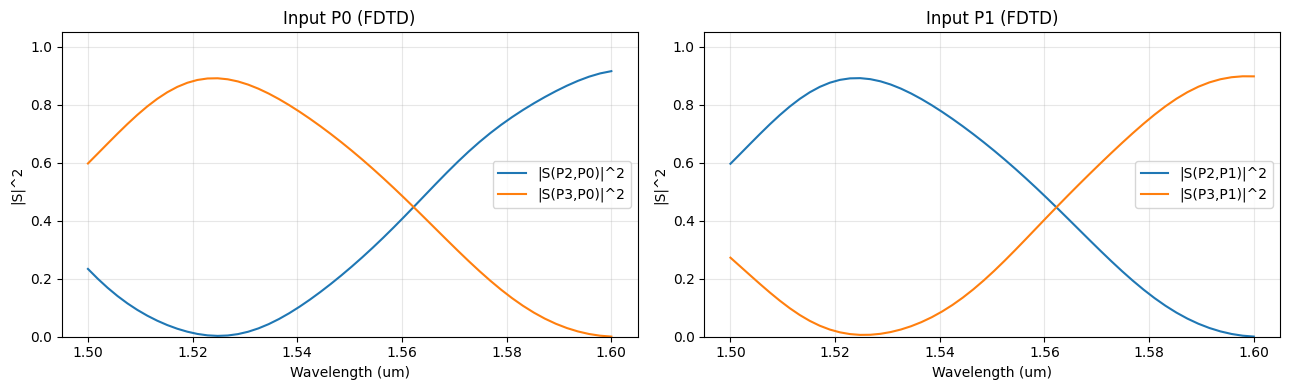

Mean excess loss for P0 input: 0.532 dB


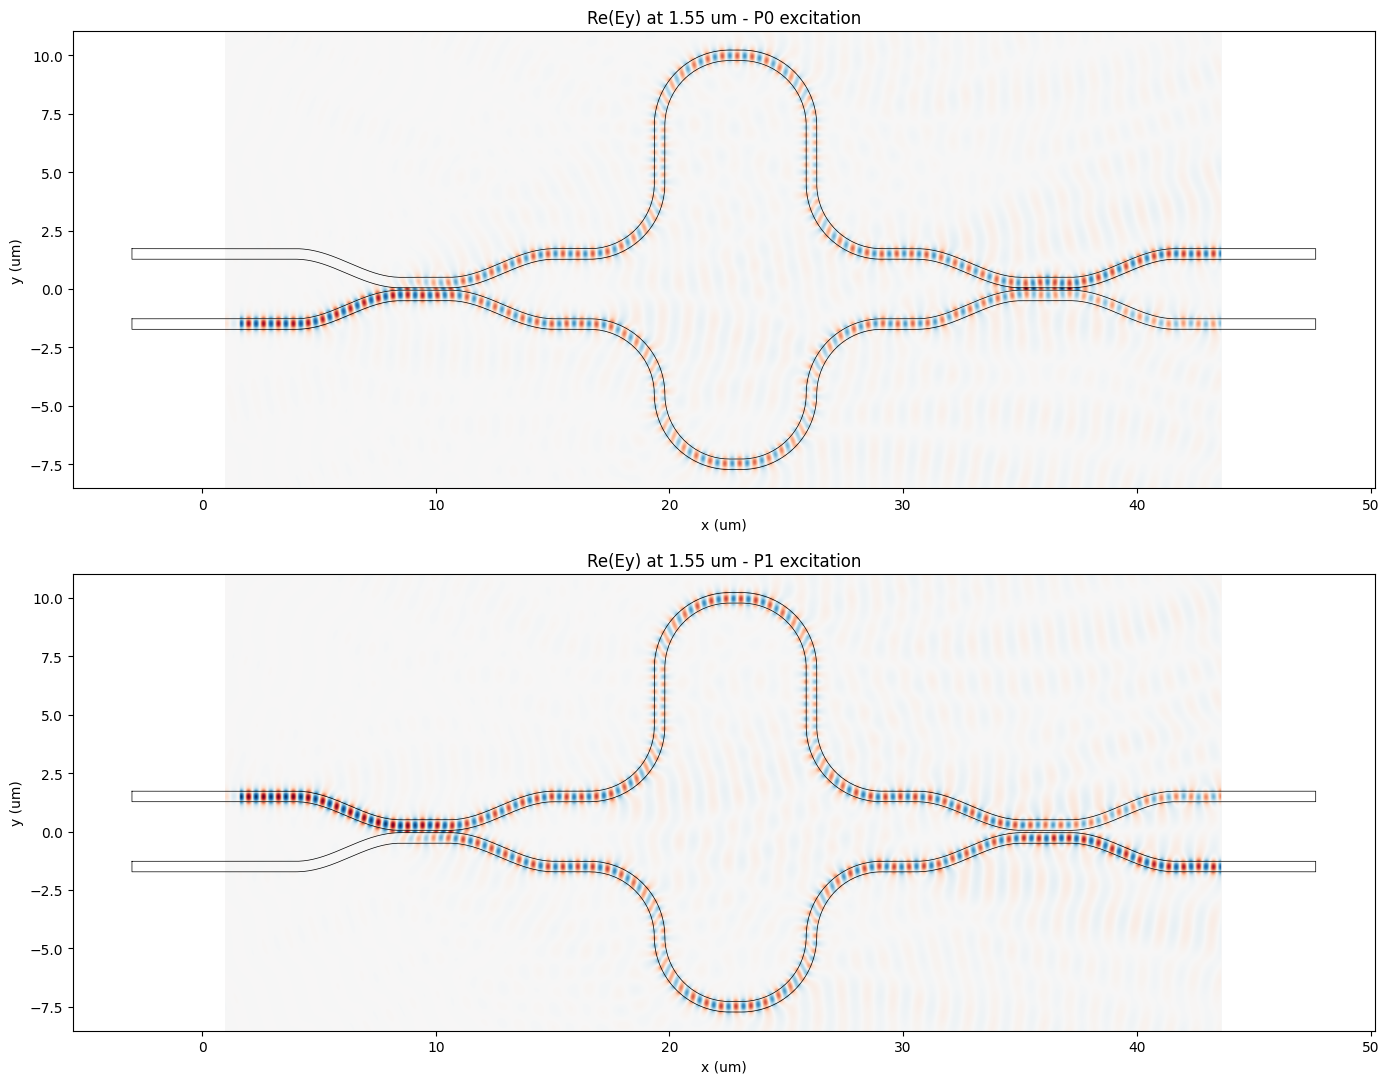

In [ ]:
dims = mzi_dims(Lc_opt, DL)
bounds = (0.0, dims["xmax"], dims["ybot"], dims["ytop"])
geo_mzi = [prism(p) for p in mzi_polys(Lc_opt, DL)]
mons4 = {"m0": (x_mon_in, -hs), "m1": (x_mon_in, hs),
         "m2": (dims["xmo"], -hs), "m3": (dims["xmo"], hs)}
path_len = dims["xmax"] + DL + 4 * R_BEND

S = {}
print("MZI: exciting P0 ...")
d0, _, fld0 = run_fdtd(geo_mzi, bounds, -hs, mons4, path_len, want_field=True, label="MZI P0")
S[("P0", "P0")] = d0["m0"][:, 1] / a_ref
S[("P0", "P1")] = d0["m1"][:, 1] / a_ref
S[("P0", "P2")] = d0["m2"][:, 0] / a_ref
S[("P0", "P3")] = d0["m3"][:, 0] / a_ref

fld1 = None
if RUN_P1:
    print("MZI: exciting P1 ...")
    d1, _, fld1 = run_fdtd(geo_mzi, bounds, +hs, mons4, path_len, want_field=True, label="MZI P1")
    S[("P1", "P1")] = d1["m1"][:, 1] / a_ref
    S[("P1", "P0")] = d1["m0"][:, 1] / a_ref
    S[("P1", "P2")] = d1["m2"][:, 0] / a_ref
    S[("P1", "P3")] = d1["m3"][:, 0] / a_ref

# ---------- S parameters (FDTD) ----------
flip = lambda a: np.asarray(a)[::-1]
lam_p = flip(lam_f)
inputs = ["P0"] + (["P1"] if RUN_P1 else [])
fig, axes = plt.subplots(1, len(inputs), figsize=(6.5 * len(inputs), 4), squeeze=False)
for ax, src in zip(axes[0], inputs):
    for out in ["P2", "P3"]:
        ax.plot(lam_p, flip(np.abs(S[(src, out)]) ** 2), label=f"|S({out},{src})|^2")
    ax.set_xlabel("Wavelength (um)"); ax.set_ylabel("|S|^2"); ax.set_ylim(0, 1.05)
    ax.set_title(f"Input {src} (FDTD)"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

tot = np.abs(S[("P0", "P2")]) ** 2 + np.abs(S[("P0", "P3")]) ** 2
print(f"Mean excess loss for P0 input: {np.mean(-10 * np.log10(tot)):.3f} dB")

# ---------- field plots at 1.55 um ----------
fields = [("P0 excitation", fld0)] + ([("P1 excitation", fld1)] if fld1 is not None else [])
fig, axes = plt.subplots(len(fields), 1, figsize=(14, 5.5 * len(fields)), squeeze=False)
ext = [bounds[0] + dpml, bounds[1] - dpml, bounds[2] + dpml, bounds[3] - dpml]
for ax, (title, f) in zip(axes[:, 0], fields):
    vmax = np.max(np.abs(f))
    ax.imshow(f.T, origin="lower", extent=ext, cmap="RdBu", vmin=-vmax, vmax=vmax, aspect="equal")
    for p in mzi_polys(Lc_opt, DL):
        ax.plot(np.append(p[:, 0], p[0, 0]), np.append(p[:, 1], p[0, 1]), "k-", lw=0.5)
    ax.set_title(f"Re(Ey) at 1.55 um - {title}"); ax.set_xlabel("x (um)"); ax.set_ylabel("y (um)")
plt.tight_layout(); plt.show()

n_eff(1.55 um) = 2.4059   n_g ~ 3.182
Expected FSR for DL = 5.0 um: 0.151 um


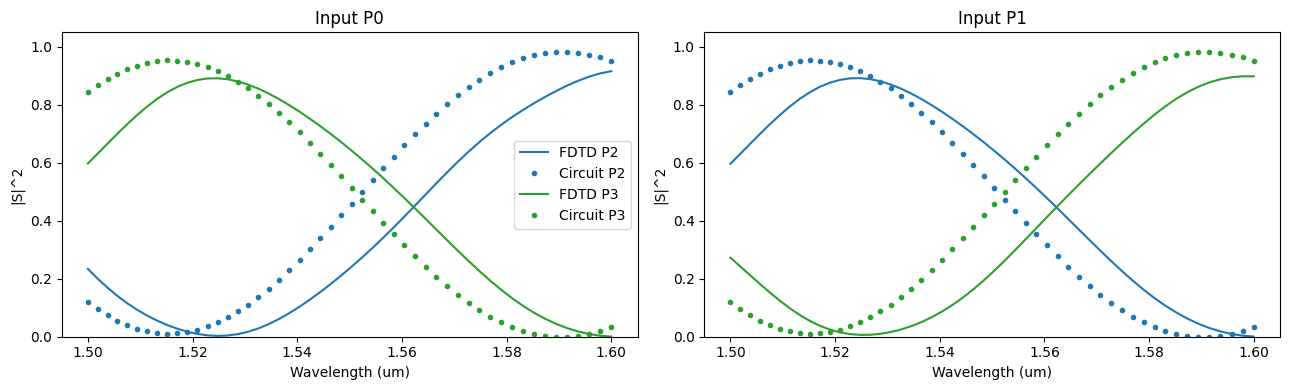

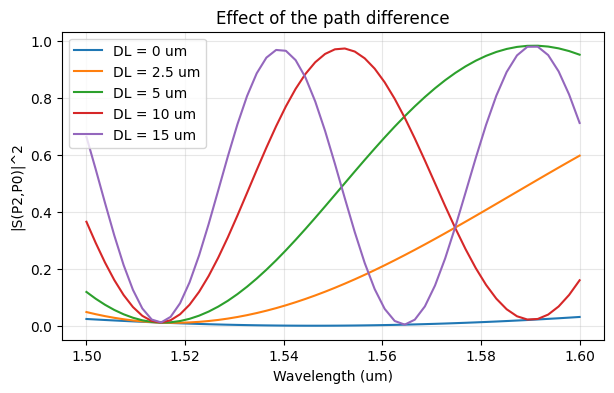

interactive(children=(FloatSlider(value=5.0, continuous_update=False, description='dl', max=20.0, step=0.5), O…

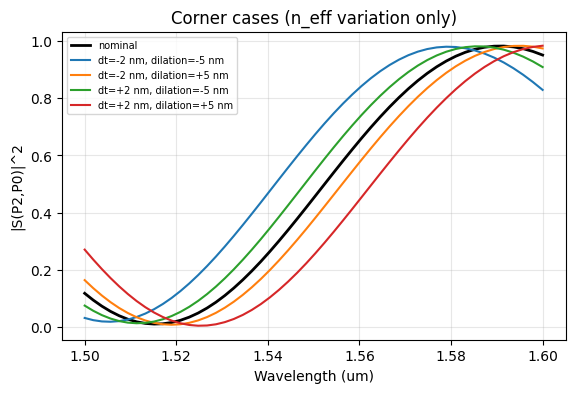

In [ ]:
# ---------- effective index from Meep's mode solver ----------
def neff_curve(freq_list, width, n_core_):
    try:
        sim = mp.Simulation(
            cell_size=mp.Vector3(1, 5, 0),
            geometry=[mp.Block(size=mp.Vector3(mp.inf, width, mp.inf), center=mp.Vector3(),
                               material=mp.Medium(index=n_core_))],
            default_material=SiO2, resolution=RES, dimensions=2)
        sim.init_sim()
        vol = mp.Volume(center=mp.Vector3(), size=mp.Vector3(0, 4, 0))
        out = []
        for f in freq_list:
            em = sim.get_eigenmode(f, mp.X, vol, 1, mp.Vector3(2.3 * f, 0, 0), parity=PARITY)
            out.append(em.k.x / f)
        return np.array(out)
    except Exception as e:
        print("WARNING: mode solver failed, using constant n_eff = 2.3. Reason:", e)
        return np.full(len(freq_list), 2.3)


f_sub = np.linspace(freqs.min(), freqs.max(), 11)
neff_sub = neff_curve(f_sub, w, n_core)
neff_nom = np.interp(freqs, f_sub, neff_sub)
lam_sub = 1.0 / f_sub
ng_sub = neff_sub - lam_sub * np.gradient(neff_sub, lam_sub)
print(f"n_eff(1.55 um) = {neff_nom[idx_c]:.4f}   n_g ~ {ng_sub[5]:.3f}")
print(f"Expected FSR for DL = {DL} um: {1.55 ** 2 / (ng_sub[5] * DL):.3f} um")
if not (n_clad < neff_nom[idx_c] < n_core):
    print("WARNING: n_eff outside the physical range - check the mode solver parity.")


def mzi_S_analytic(neff, lam, t, k, DLx):
    """Circuit model: coupler - two arms - coupler. Keys are (input, output)."""
    dphi = 2 * np.pi * neff * DLx / lam
    e_l, e_u = np.ones_like(lam, dtype=complex), np.exp(-1j * dphi)
    ic = 1j * k
    M00 = t * e_l * t + ic * e_u * ic
    M10 = ic * e_l * t + t * e_u * ic
    M01 = t * e_l * ic + ic * e_u * t
    M11 = ic * e_l * ic + t * e_u * t
    return {("P0", "P2"): M00, ("P0", "P3"): M10, ("P1", "P2"): M01, ("P1", "P3"): M11}


S_an = mzi_S_analytic(neff_nom, lam_f, t_c, k_c, DL)

# ---------- FDTD vs circuit model (like the Tidy3D comparison in the original) ----------
fig, axes = plt.subplots(1, len(inputs), figsize=(6.5 * len(inputs), 4), squeeze=False)
for ax, src in zip(axes[0], inputs):
    for out in ["P2", "P3"]:
        line = ax.plot(lam_p, flip(np.abs(S[(src, out)]) ** 2), "-")[0]
        ax.plot(lam_p, flip(np.abs(S_an[(src, out)]) ** 2), ".",
                mfc=line.get_color(), mec=line.get_color())
    ax.set_xlabel("Wavelength (um)"); ax.set_ylabel("|S|^2"); ax.set_ylim(0, 1.05)
    ax.set_title(f"Input {src}")
axes[0][0].legend(["FDTD P2", "Circuit P2", "FDTD P3", "Circuit P3"])
plt.tight_layout(); plt.show()

# ---------- exploring the path difference (semi-analytical) ----------
plt.figure(figsize=(7, 4))
for dl in [0, 2.5, 5, 10, 15]:
    s = mzi_S_analytic(neff_nom, lam_f, t_c, k_c, dl)
    plt.plot(lam_p, flip(np.abs(s[("P0", "P2")]) ** 2), label=f"DL = {dl} um")
plt.xlabel("Wavelength (um)"); plt.ylabel("|S(P2,P0)|^2"); plt.grid(alpha=0.3); plt.legend()
plt.title("Effect of the path difference"); plt.show()

try:
    from ipywidgets import FloatSlider, interactive
    from IPython.display import display

    def _update(dl):
        s = mzi_S_analytic(neff_nom, lam_f, t_c, k_c, dl)
        plt.figure(figsize=(6, 3.5))
        for out in ["P2", "P3"]:
            plt.plot(lam_p, flip(np.abs(s[("P0", out)]) ** 2), label=f"|S({out},P0)|^2")
        plt.ylim(0, 1.05); plt.xlabel("Wavelength (um)"); plt.legend(); plt.grid(alpha=0.3)
        plt.show()

    display(interactive(_update, dl=FloatSlider(value=DL, min=0, max=20, step=0.5,
                                                continuous_update=False)))
except Exception as e:
    print("Slider not available:", e)

# ---------- corner cases (thickness +-2 nm, mask dilation +-5 nm) ----------
plt.figure(figsize=(6.5, 4))
plt.plot(lam_p, flip(np.abs(S_an[("P0", "P2")]) ** 2), "k-", lw=2, label="nominal")
for dt in (-0.002, +0.002):
    for dd in (-0.005, +0.005):
        n_c = slab_neff(t_si + dt)
        neff_c = np.interp(freqs, f_sub, neff_curve(f_sub, w + 2 * dd, n_c))
        s = mzi_S_analytic(neff_c, lam_f, t_c, k_c, DL)
        plt.plot(lam_p, flip(np.abs(s[("P0", "P2")]) ** 2),
                 label=f"dt={dt * 1e3:+.0f} nm, dilation={dd * 1e3:+.0f} nm")
plt.xlabel("Wavelength (um)"); plt.ylabel("|S(P2,P0)|^2"); plt.grid(alpha=0.3)
plt.legend(fontsize=7); plt.title("Corner cases (n_eff variation only)"); plt.show()

In [ ]:
np.savez("MZI_meep_results.npz", wavelength_um=lam_p,
         **{f"S_{i}_{j}": flip(v) for (i, j), v in S.items()})
print("Saved MZI_meep_results.npz")

try:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gdstk"], check=True)
    import gdstk
    DL_FINAL = 10.0                                    # final_mzi = single_mzi(10) in the original
    d_f = mzi_dims(Lc_opt, DL_FINAL)
    polys = mzi_polys(Lc_opt, DL_FINAL, x_start=xc0 - 3.0, x_stop=d_f["x2e"] + 3.0)
    lib = gdstk.Library()
    cell = lib.new_cell("MZI")
    for p in polys:
        cell.add(gdstk.Polygon([tuple(v) for v in p], layer=2, datatype=0))   # WG_CORE (2,0)
    lib.write_gds("MZI.gds")
    chk = gdstk.read_gds("MZI.gds")
    print("GDS written; polygons:", sum(len(c.polygons) for c in chk.cells))
except Exception as e:
    print("GDS export skipped:", e)

# from google.colab import files; files.download("MZI.gds")

Saved MZI_meep_results.npz
GDS written; polygons: 10
